<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week4/lesson14/Lesson14_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 14 — Multivariable Gradients: Slopes in Many Directions

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 4 — Calculus II\
**Lesson:** Lesson 14\
**Notebook type:** Teaching notebook

> *"On a hillside, 'how steep is it?' has no single answer until you say which way you are walking. The gradient answers for every direction at once."*

---

### From one input to many

Lessons 8–13 studied functions of **one** variable. Almost nothing in neuroscience is that simple. A place cell's firing rate depends on an animal's position $(x, y)$; a visual neuron's rate depends on the contrast of stimuli on the left and the right $(c_L, c_R)$; a loss depends on every weight of a model. This lesson extends derivatives to functions of several variables:

- **partial derivatives** measure the slope along one input while the others are held fixed;
- the **gradient** collects them into a vector that points uphill, and **contour maps** show its geometry;
- the **directional derivative** gives the slope along any direction;
- the **Hessian** generalises the second derivative and classifies critical points as minima, maxima or **saddles**;
- **feature scaling and units** decide what the size of a gradient means.

The mini-lab maps how a mouse visual-cortex neuron's firing depends on two contrasts, finds that the data and a model agree on the **gradient** but disagree on the **curvature**, combines partial derivatives into a **directional derivative**, and finds that measuring one contrast in percent instead of as a fraction makes the fitting problem a thousand times worse conditioned.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-13.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**. 3-D surfaces can be rotated with the mouse.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-13.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

def numerical_gradient(f, p, h=1e-5):
    # Central-difference gradient of f at the point p (any number of inputs), shape (d,).
    p = np.asarray(p, float); g = np.zeros_like(p)
    for i in range(p.size):
        e = np.zeros_like(p); e[i] = h
        g[i] = (f(p + e) - f(p - e)) / (2 * h)
    return g

def numerical_hessian(f, p, h=1e-4):
    # Central-difference Hessian of f at p, shape (d, d).
    p = np.asarray(p, float); d = p.size; H = np.zeros((d, d))
    for i in range(d):
        for j in range(d):
            ei, ej = np.eye(d)[i] * h, np.eye(d)[j] * h
            H[i, j] = (f(p + ei + ej) - f(p + ei - ej) - f(p - ei + ej) + f(p - ei - ej)) / (4 * h * h)
    return H

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: a place cell's map of space**

A hippocampal **place cell** fires when an animal is in one region of its environment, the cell's **place field**. A standard model is a Gaussian bump on a baseline:

$$r(x, y) = r_0 + r_{\max}\exp\!\Big(-\frac{(x - x_0)^2 + (y - y_0)^2}{2s^2}\Big),$$

with position $(x, y)$ in cm, field centre $(x_0, y_0) = (60, 40)$ cm, width $s = 15$ cm, baseline $r_0 = 0.5$ spikes/s and peak increase $r_{\max} = 20$ spikes/s. The rate is a **function of two variables**: a surface over the floor of a 100 cm × 80 cm box. Three ways to draw it are a 3-D surface, a heat map, and a **contour map** whose lines join points of equal rate, like the height lines on a hiking map.

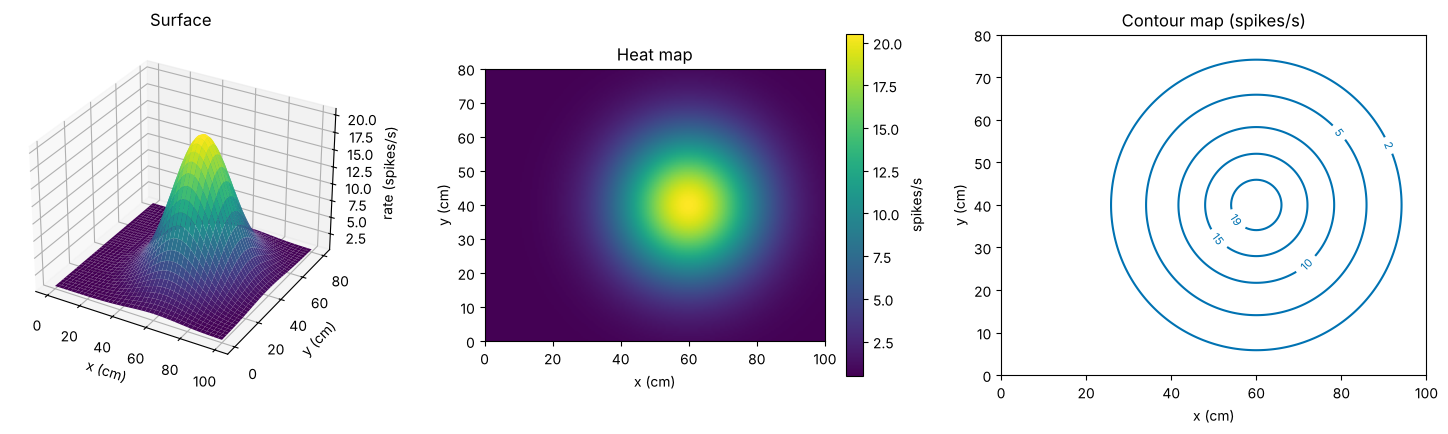

In [3]:
x0_pf, y0_pf, s_pf, r0_pf, rmax_pf = 60.0, 40.0, 15.0, 0.5, 20.0
def place_rate(x, y):
    return r0_pf + rmax_pf * np.exp(-((x - x0_pf)**2 + (y - y0_pf)**2) / (2 * s_pf**2))   # spikes/s

xg = np.linspace(0, 100, 201); yg = np.linspace(0, 80, 161)
Xg, Yg = np.meshgrid(xg, yg)                                         # (161, 201) grids: rows = y, columns = x
R_pf = place_rate(Xg, Yg)                                            # (161, 201) rate map, spikes/s

fig = plt.figure(figsize=(15, 4.2))
ax3 = fig.add_subplot(1, 3, 1, projection='3d')
ax3.plot_surface(Xg, Yg, R_pf, cmap='viridis', linewidth=0, antialiased=True)
ax3.set_xlabel('x (cm)'); ax3.set_ylabel('y (cm)'); ax3.set_zlabel('rate (spikes/s)'); ax3.set_title('Surface')
ax2 = fig.add_subplot(1, 3, 2)
im = ax2.imshow(R_pf, origin='lower', extent=[0, 100, 0, 80], cmap='viridis', aspect='equal')
plt.colorbar(im, ax=ax2, label='spikes/s'); ax2.set_xlabel('x (cm)'); ax2.set_ylabel('y (cm)'); ax2.set_title('Heat map')
ax1 = fig.add_subplot(1, 3, 3)
cs = ax1.contour(Xg, Yg, R_pf, levels=[2, 5, 10, 15, 19], colors=[PALETTE[0]])
ax1.clabel(cs, fontsize=8, fmt='%g'); ax1.set_aspect('equal'); ax1.set_xlabel('x (cm)'); ax1.set_ylabel('y (cm)'); ax1.set_title('Contour map (spikes/s)')
plt.tight_layout(); plt.show()

How sensitive is this neuron to the animal's position? At the centre, not at all: small moves barely change the rate. On the flank of the field, very: but **the answer depends on the direction of the move**. Moving around the field (along a contour) keeps the rate constant; moving towards the centre raises it fastest. The tools of this lesson make this precise.

# **Part 1: Functions of Several Variables and Partial Derivatives**

A function of $d$ variables, $f(x_1, \dots, x_d)$, or $f(\mathbf{x})$ with $\mathbf{x} \in \mathbb{R}^d$, assigns a number to every point of $d$-dimensional space. Examples: a rate map $r(x, y)$; a loss $L(w_1, w_2, b)$; a tuning model $r(v_x, v_y)$.

The **partial derivative** with respect to $x_i$ is the ordinary derivative along $x_i$ with all other inputs **held fixed**:

$$\frac{\partial f}{\partial x}(x, y) = \lim_{h\to0}\frac{f(x + h, y) - f(x, y)}{h},\qquad \frac{\partial f}{\partial y}(x, y) = \lim_{h\to0}\frac{f(x, y + h) - f(x, y)}{h}.$$

Geometrically, $\partial f/\partial x$ is the slope of the **slice** of the surface cut parallel to the $x$-axis. All the rules of Lesson 9 apply, treating the other variables as constants. For the place field, writing $g = \exp\!\big(-\frac{(x - x_0)^2 + (y - y_0)^2}{2s^2}\big)$,

$$\frac{\partial r}{\partial x} = -r_{\max}\,g\,\frac{x - x_0}{s^2},\qquad \frac{\partial r}{\partial y} = -r_{\max}\,g\,\frac{y - y_0}{s^2}.$$

**Units.** Each partial derivative has the units of the output per unit of **its own** input: here spikes/s per cm. With inputs in different units (a speed in cm/s and a position in cm, say), the partial derivatives have different units and cannot be compared directly (Part 4).

**Numerically**, take a central difference along each input in turn, $\frac{\partial f}{\partial x} \approx \frac{f(x + h, y) - f(x - h, y)}{2h}$. For a function sampled on a grid, `np.gradient` does this along each axis.

at (x, y) = [45. 50.] cm: rate 10.213 spikes/s
  formula:   dr/dx = +0.6476, dr/dy = -0.4317 spikes/s per cm
  numerical: [ 0.6476 -0.4317]
  np.gradient on the 0.5 cm grid: dr/dx = +0.6473, dr/dy = -0.4315


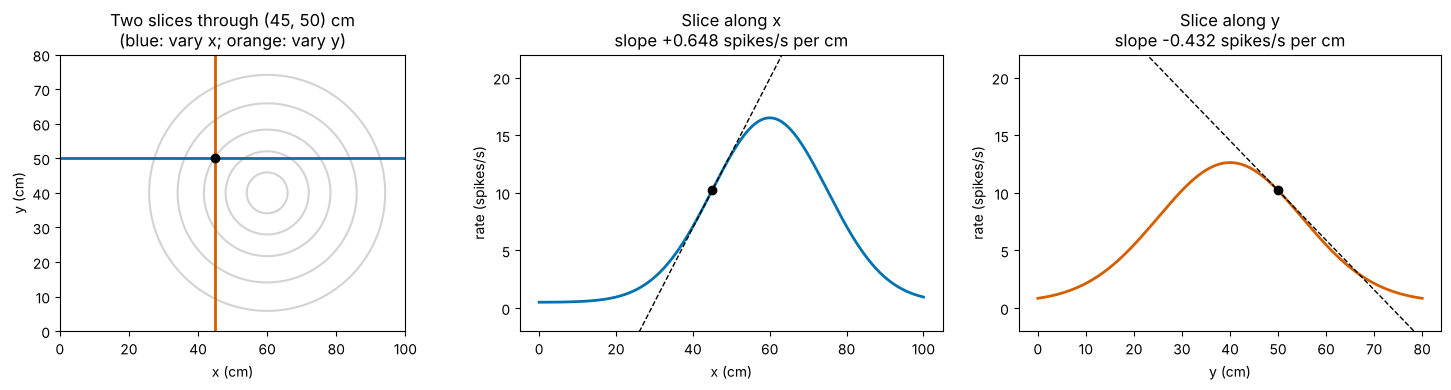

In [4]:
def dr_dx(x, y):
    g = np.exp(-((x - x0_pf)**2 + (y - y0_pf)**2) / (2 * s_pf**2))
    return -rmax_pf * g * (x - x0_pf) / s_pf**2
def dr_dy(x, y):
    g = np.exp(-((x - x0_pf)**2 + (y - y0_pf)**2) / (2 * s_pf**2))
    return -rmax_pf * g * (y - y0_pf) / s_pf**2

p_test = np.array([45.0, 50.0])                                       # a point on the flank of the field, cm
f_pf = lambda p: place_rate(p[0], p[1])
print(f"at (x, y) = {p_test} cm: rate {f_pf(p_test):.3f} spikes/s")
print(f"  formula:   dr/dx = {dr_dx(*p_test):+.4f}, dr/dy = {dr_dy(*p_test):+.4f} spikes/s per cm")
print(f"  numerical: {np.round(numerical_gradient(f_pf, p_test), 4)}")
gy_grid, gx_grid = np.gradient(R_pf, yg, xg)                           # np.gradient returns one array per axis: rows (y) first
i_y, i_x = np.searchsorted(yg, 50.0), np.searchsorted(xg, 45.0)
print(f"  np.gradient on the 0.5 cm grid: dr/dx = {gx_grid[i_y, i_x]:+.4f}, dr/dy = {gy_grid[i_y, i_x]:+.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].contour(Xg, Yg, R_pf, levels=[2, 5, 10, 15, 19], colors=['lightgrey'])
axes[0].axhline(50, color=PALETTE[0], lw=2, label='slice y = 50 cm (vary x)')
axes[0].axvline(45, color=PALETTE[1], lw=2, label='slice x = 45 cm (vary y)')
axes[0].plot(*p_test, 'ko'); axes[0].set_aspect('equal'); axes[0].set_xlabel('x (cm)'); axes[0].set_ylabel('y (cm)'); axes[0].set_title('Two slices through (45, 50) cm\n(blue: vary x; orange: vary y)')
for ax, var, colour in [(axes[1], 'x', PALETTE[0]), (axes[2], 'y', PALETTE[1])]:
    tvals = np.linspace(0, 100, 300) if var == 'x' else np.linspace(0, 80, 300)
    rr = place_rate(tvals, 50.0) if var == 'x' else place_rate(45.0, tvals)
    slope = dr_dx(*p_test) if var == 'x' else dr_dy(*p_test)
    c0 = p_test[0] if var == 'x' else p_test[1]
    ax.plot(tvals, rr, color=colour, lw=2)
    ax.plot(tvals, f_pf(p_test) + slope * (tvals - c0), color='black', ls='--', lw=1)
    ax.plot(c0, f_pf(p_test), 'ko'); ax.set_ylim(-2, 22)
    ax.set_xlabel(f'{var} (cm)'); ax.set_ylabel('rate (spikes/s)'); ax.set_title(f'Slice along {var}\nslope {slope:+.3f} spikes/s per cm')
plt.tight_layout(); plt.show()

#### Interactive version: rotate the surface

In [5]:
fig_s = go.Figure([go.Surface(x=xg[::4], y=yg[::4], z=np.round(R_pf[::4, ::4], 3), colorscale='Viridis', colorbar=dict(title='spikes/s'),
                              contours=dict(z=dict(show=True, usecolormap=True, project_z=True)))])
fig_s.update_layout(title='Place-field rate surface, with its contours projected on the floor', template='plotly_white', width=850, height=560,
                    scene=dict(xaxis_title='x (cm)', yaxis_title='y (cm)', zaxis_title='rate (spikes/s)'))
fig_s.show(config=PLOTLY_CONFIG)

# **Part 2: The Gradient, Directional Derivatives and Contour Maps**

The **gradient** collects the partial derivatives into a vector:

$$\nabla f(\mathbf{x}) = \Big(\frac{\partial f}{\partial x_1}, \dots, \frac{\partial f}{\partial x_d}\Big)^{\mathsf T}.$$

**Linear approximation.** As in Lesson 9, near a point $\mathbf{x}$ a smooth function is approximately a **plane** (a hyperplane in more dimensions):

$$f(\mathbf{x} + \mathbf{h}) \approx f(\mathbf{x}) + \nabla f(\mathbf{x})\cdot\mathbf{h} .$$

The change is a **dot product** (Lesson 2) of the gradient with the step.

**Directional derivative.** For a **unit** vector $\mathbf{u}$ (a direction), the slope along $\mathbf{u}$ is

$$D_{\mathbf{u}}f = \nabla f\cdot\mathbf{u} = \lVert\nabla f\rVert\cos\phi,$$

where $\phi$ is the angle between $\mathbf{u}$ and $\nabla f$. Three facts follow at once:
1. The slope is **largest**, $\lVert\nabla f\rVert$, along $\mathbf{u} = \nabla f/\lVert\nabla f\rVert$: **the gradient points uphill, in the direction of steepest ascent**, and its length is the steepest slope. ($-\nabla f$ points steepest downhill: the direction of gradient descent, Lesson 15.)
2. The slope is **zero** perpendicular to the gradient: moving along a **contour** (level set, $f = $ const) does not change $f$. So **the gradient is perpendicular to the contour lines**.
3. As the direction turns, the slope varies like a **cosine** of the angle to the gradient. (Keep this in mind for the mini-lab.)

**Reading a contour map.** Closely spaced contours mean a large gradient (steep); widely spaced ones mean a small gradient (flat); closed rings around a point mark a peak or a pit; crossing contour patterns ("X" shapes) mark saddles.

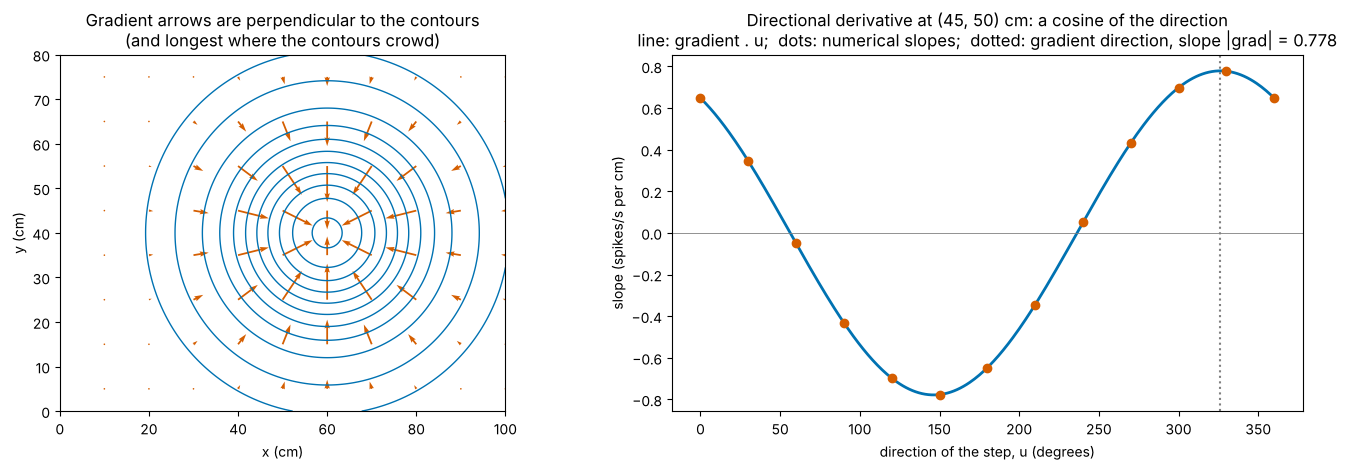

gradient at [45. 50.]: [ 0.6476 -0.4317] spikes/s per cm;  it points towards the field centre: [ 0.832 -0.555]


In [6]:
xq, yq = np.meshgrid(np.linspace(10, 100, 10), np.linspace(5, 75, 8))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].contour(Xg, Yg, R_pf, levels=[1, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20], colors=[PALETTE[0]], linewidths=1)
axes[0].quiver(xq, yq, dr_dx(xq, yq), dr_dy(xq, yq), color=PALETTE[1], angles='xy', scale_units='xy', scale=0.1, width=0.004)
axes[0].set_aspect('equal'); axes[0].set_xlabel('x (cm)'); axes[0].set_ylabel('y (cm)')
axes[0].set_title('Gradient arrows are perpendicular to the contours\n(and longest where the contours crowd)')
grad_p = np.array([dr_dx(*p_test), dr_dy(*p_test)])
angles = np.linspace(0, 2 * np.pi, 361)
D_u = grad_p[0] * np.cos(angles) + grad_p[1] * np.sin(angles)         # directional derivative for each unit direction
numeric_Du = [(f_pf(p_test + 1e-5 * np.array([np.cos(a), np.sin(a)])) - f_pf(p_test - 1e-5 * np.array([np.cos(a), np.sin(a)]))) / 2e-5 for a in angles[::30]]
axes[1].plot(np.degrees(angles), D_u, color=PALETTE[0], lw=2, label='gradient . u')
axes[1].plot(np.degrees(angles[::30]), numeric_Du, 'o', color=PALETTE[1], label='numerical slope along u')
ang_g = np.degrees(np.arctan2(grad_p[1], grad_p[0])) % 360
axes[1].axvline(ang_g, color='grey', ls=':', label=f'gradient direction ({ang_g:.0f} deg): slope = |grad| = {np.linalg.norm(grad_p):.3f}')
axes[1].axhline(0, color='grey', lw=0.6)
axes[1].set_xlabel('direction of the step, u (degrees)'); axes[1].set_ylabel('slope (spikes/s per cm)'); axes[1].set_title(f'Directional derivative at ({p_test[0]:.0f}, {p_test[1]:.0f}) cm: a cosine of the direction\nline: gradient . u;  dots: numerical slopes;  dotted: gradient direction, slope |grad| = {np.linalg.norm(grad_p):.3f}')
plt.tight_layout(); plt.show()
print(f"gradient at {p_test}: {np.round(grad_p, 4)} spikes/s per cm;  it points towards the field centre: {np.round((np.array([x0_pf, y0_pf]) - p_test) / np.linalg.norm(np.array([x0_pf, y0_pf]) - p_test), 3)}")

#### Interactive version: turn the direction of the step
The arrow shows a unit step direction $\mathbf{u}$ from the point $(45, 50)$ cm; the title gives the slope along it.

In [7]:
angs = np.arange(0, 360, 15)
def dir_trace(a_deg):
    a = np.radians(a_deg)
    return [p_test[0], p_test[0] + 12 * np.cos(a)], [p_test[1], p_test[1] + 12 * np.sin(a)]
cx, cy = dir_trace(0)
fig_d = go.Figure([go.Contour(x=xg[::2], y=yg[::2], z=np.round(R_pf[::2, ::2], 3), colorscale='Viridis', contours=dict(showlabels=True), colorbar=dict(title='spikes/s'), opacity=0.8),
                   go.Scatter(x=cx, y=cy, mode='lines+markers', line=dict(color='white', width=4), marker=dict(size=[6, 12], color='white'), name='direction u'),
                   go.Scatter(x=[p_test[0], p_test[0] + 12 * grad_p[0] / np.linalg.norm(grad_p)], y=[p_test[1], p_test[1] + 12 * grad_p[1] / np.linalg.norm(grad_p)],
                              mode='lines', line=dict(color='red', width=3, dash='dot'), name='gradient direction')])
fig_d.frames = [go.Frame(name=str(k), traces=[1], data=[go.Scatter(x=dir_trace(a)[0], y=dir_trace(a)[1])],
                         layout=go.Layout(title=f'u at {a} deg: slope = grad . u = {grad_p[0] * np.cos(np.radians(a)) + grad_p[1] * np.sin(np.radians(a)):+.3f} spikes/s per cm'))
                for k, a in enumerate(angs)]
buttons, sliders = play_pause_and_slider(list(angs), prefix='direction (deg) = ', duration=300)
fig_d.update_layout(title=fig_d.frames[0].layout.title.text, xaxis=dict(title='x (cm)', range=[0, 100]), yaxis=dict(title='y (cm)', range=[0, 80], scaleanchor='x'),
                    template='plotly_white', width=850, height=560, updatemenus=buttons, sliders=sliders)
fig_d.show(config=PLOTLY_CONFIG)

# **Part 3: Critical Points in Several Dimensions; the Hessian**

A **critical point** has $\nabla f = \mathbf{0}$: the tangent plane is flat. In one dimension a critical point was a minimum, a maximum or a stationary inflection (Lesson 11). In two or more dimensions there is a new, very common possibility, the **saddle**: uphill in some directions and downhill in others, like a mountain pass.

The second-order information is the **Hessian**, the symmetric matrix of second partial derivatives,

$$\mathbf{H} = \begin{pmatrix}\frac{\partial^2f}{\partial x^2} & \frac{\partial^2f}{\partial x\partial y}\\[3pt] \frac{\partial^2f}{\partial y\partial x} & \frac{\partial^2f}{\partial y^2}\end{pmatrix},\qquad f(\mathbf{x}^* + \mathbf{h}) \approx f(\mathbf{x}^*) + \tfrac12\mathbf{h}^{\mathsf T}\mathbf{H}\,\mathbf{h}\quad\text{at a critical point}.$$

(The mixed partials are equal for smooth functions, so $\mathbf{H}$ is symmetric.) Its eigenvectors are perpendicular directions and its eigenvalues are the **curvatures** along them (Lessons 6 and 11). The **second-derivative test**:

| Eigenvalues of $\mathbf{H}$ | Type | Contours nearby |
|---|---|---|
| all $> 0$ | local **minimum** | ellipses |
| all $< 0$ | local **maximum** | ellipses |
| some $> 0$, some $< 0$ | **saddle** | crossing hyperbolas |
| some $= 0$ | inconclusive (flat direction) | — |

For a $2\times2$ Hessian: $\det\mathbf{H} = \lambda_1\lambda_2 < 0$ means a saddle; $\det > 0$ with trace $> 0$ a minimum; $\det > 0$ with trace $< 0$ a maximum (as for the stability tests of Lesson 6).

**Neural example.** Two place cells with nearby fields, or one neuron with **two** subfields: the summed map has two peaks, and between them a saddle. In high-dimensional losses (neural networks), saddles vastly outnumber local minima, and gradient descent slows down near them.

critical point (35.71, 40.10) cm: rate 12.23 spikes/s; Hessian eigenvalues [-0.0849 -0.0702] -> maximum;  det = +5.96e-03
critical point (69.63, 44.95) cm: rate 16.16 spikes/s; Hessian eigenvalues [-0.1122 -0.102 ] -> maximum;  det = +1.15e-02
critical point (50.34, 42.19) cm: rate 9.28 spikes/s; Hessian eigenvalues [-0.0645  0.0733] -> saddle;  det = -4.72e-03


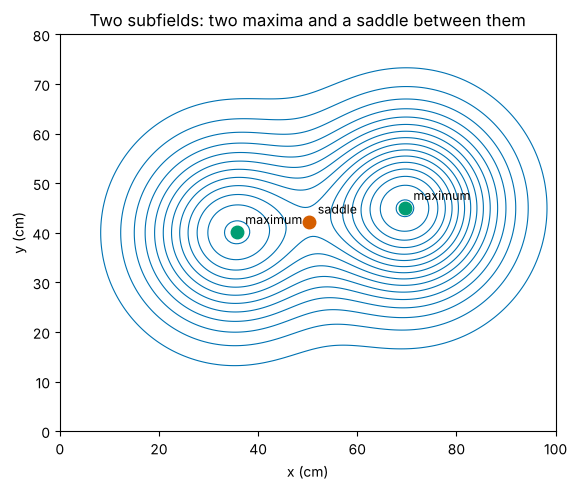

In [8]:
def two_fields(p):
    x, y = p
    return (12 * np.exp(-((x - 35)**2 + (y - 40)**2) / (2 * 12**2)) +
            16 * np.exp(-((x - 70)**2 + (y - 45)**2) / (2 * 12**2)))
R2 = two_fields((Xg, Yg))
crit_pts = []
from scipy.optimize import minimize
for start in [(35, 40), (70, 45), (52, 42)]:
    # Find points where the gradient vanishes by minimising |grad|^2 from several starts.
    res = minimize(lambda p: np.sum(numerical_gradient(two_fields, p)**2), start, method='Nelder-Mead', options={'xatol': 1e-8, 'fatol': 1e-14, 'maxiter': 4000})
    crit_pts.append(res.x)
fig, ax = plt.subplots(figsize=(8, 5))
cs = ax.contour(Xg, Yg, R2, levels=np.arange(1, 17, 1.0), colors=[PALETTE[0]], linewidths=0.8)
for p in crit_pts:
    H = numerical_hessian(two_fields, p)
    ev = np.linalg.eigvalsh(H)
    kind = 'maximum' if np.all(ev < 0) else ('minimum' if np.all(ev > 0) else 'saddle')
    ax.plot(*p, 'o', color=PALETTE[1] if kind == 'saddle' else PALETTE[2], ms=9)
    ax.annotate(kind, p, textcoords='offset points', xytext=(6, 6), fontsize=9)
    print(f"critical point ({p[0]:.2f}, {p[1]:.2f}) cm: rate {two_fields(p):.2f} spikes/s; Hessian eigenvalues {np.round(ev, 4)} -> {kind};  det = {np.linalg.det(H):+.2e}")
ax.set_aspect('equal'); ax.set_xlabel('x (cm)'); ax.set_ylabel('y (cm)'); ax.set_title('Two subfields: two maxima and a saddle between them')
plt.tight_layout(); plt.show()

#### The three basic shapes

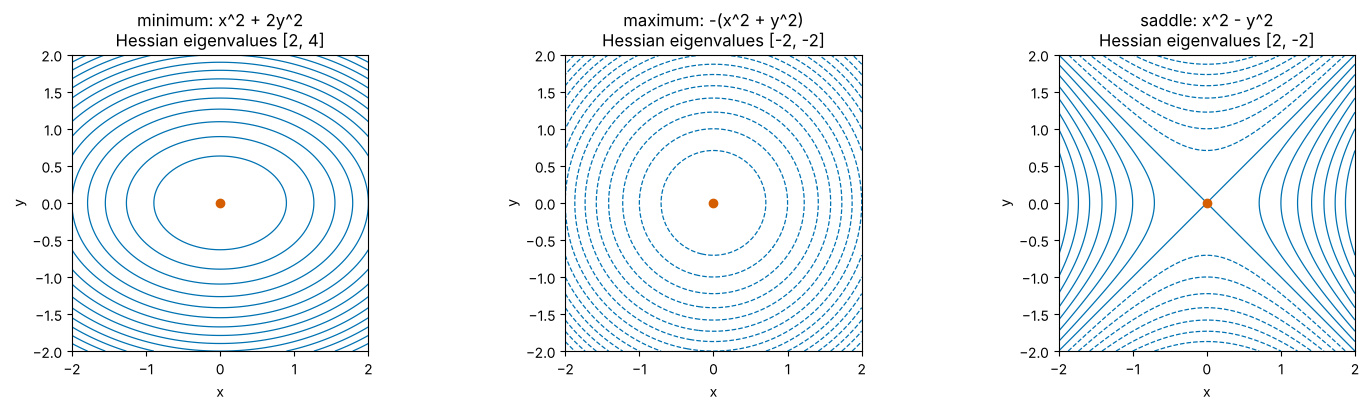

In [9]:
u = np.linspace(-2, 2, 101); U, Vv = np.meshgrid(u, u)
shapes = [('minimum: x^2 + 2y^2', U**2 + 2 * Vv**2, [2, 4]), ('maximum: -(x^2 + y^2)', -(U**2 + Vv**2), [-2, -2]), ('saddle: x^2 - y^2', U**2 - Vv**2, [2, -2])]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (title, Z, ev) in zip(axes, shapes):
    ax.contour(U, Vv, Z, levels=15, colors=[PALETTE[0]], linewidths=0.9)
    ax.plot(0, 0, 'o', color=PALETTE[1])
    ax.set_aspect('equal'); ax.set_title(f'{title}\nHessian eigenvalues {ev}'); ax.set_xlabel('x'); ax.set_ylabel('y')
plt.tight_layout(); plt.show()

# **Part 4: Feature Scaling, Units, and the Size of a Gradient**

The gradient of a loss $L(\mathbf{w})$ with respect to the weights of a model $\hat y = \mathbf{w}\cdot\mathbf{x}$ has components $\partial L/\partial w_i$ in units of [loss] per [unit of $w_i$], and $w_i$ itself has units of [output] per [unit of feature $x_i$]. So:

- **Rescaling a feature rescales its weight and its gradient component.** If $x_1$ is measured in m instead of cm (100 times smaller numbers), its weight becomes 100 times larger, $\partial L/\partial w_1$ 100 times larger, and the curvature $\partial^2L/\partial w_1^2$ $10^4$ times larger. The predictions do not change at all.
- **The size of a gradient component is not the importance of a feature.** A large $\partial f/\partial x_i$ may just mean $x_i$ is measured in large units of small numbers. Compare sensitivities only after putting features on a common scale, for example **standardising** (subtract the mean, divide by the SD: Lesson 3), so each partial derivative means "change per standard deviation of that feature".
- **The direction of the gradient depends on the units.** The "steepest" direction is steepest per unit length, and length mixes the units of all inputs. Rescaling one input rotates the gradient. Only the **level sets** (the contours of the function itself) are unit-free.
- **Badly scaled features make the loss surface an elongated valley** (Lesson 11): the Hessian $\frac1n\mathbf{X}^{\mathsf T}\mathbf{X}$ (for squared error) has a large condition number, and gradient descent zig-zags (Lesson 15). Standardising makes the contours rounder.

Below, a linear model predicts a rate from two features of a reaching movement: peak speed (cm/s, SD about 3) and reach distance (SD about 2 cm, expressed once in cm and once in m). Longer reaches are faster, so the two features are correlated (about 0.6).

speed (cm/s), distance (cm)        weights [2.15 1.4 ];  gradient at w = 0: [-21.555 -11.901];  Hessian condition number 5
speed (cm/s), distance (m)         weights [  2.15  139.959];  gradient at w = 0: [-21.555  -0.119];  Hessian condition number 33,885
both standardised                  weights [6.064 2.662];  gradient at w = 0: [-7.642 -6.256];  Hessian condition number 4


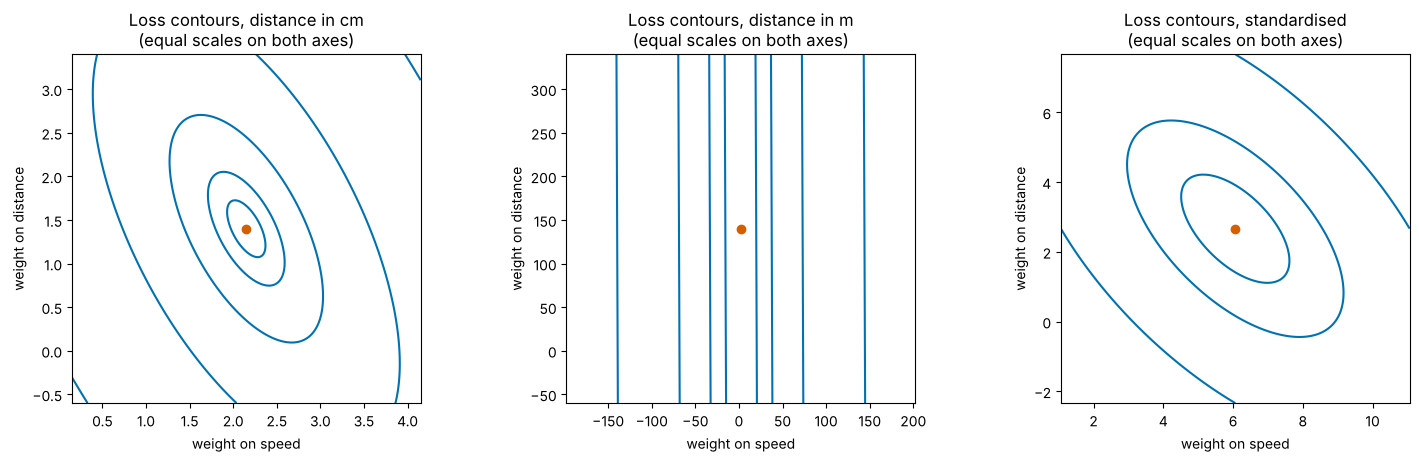

In [10]:
n_f = 400
dist_cm = RNG.normal(10, 2, n_f)                                       # (400,) reach distance, cm
speed_f = 0.8 * dist_cm + RNG.gamma(4, 1.2, n_f)                       # (400,) peak speed, cm/s (longer reaches are faster)
rate_f = 2.0 * speed_f + 1.5 * dist_cm + RNG.normal(0, 3, n_f)          # (400,) spikes/s
def summarise(X, label):
    Xc = X - X.mean(axis=0)
    H = Xc.T @ Xc / len(X)                                             # Hessian of (1/2n)||y - X w||^2 after centring (intercept removed)
    w = np.linalg.lstsq(Xc, rate_f - rate_f.mean(), rcond=None)[0]
    g0 = -Xc.T @ (rate_f - rate_f.mean()) / len(X)                     # gradient at w = 0
    ev = np.linalg.eigvalsh(H)
    print(f"{label:<34} weights {np.round(w, 3)};  gradient at w = 0: {np.round(g0, 3)};  Hessian condition number {ev[-1] / ev[0]:,.0f}")
    return Xc, w
X_cm = np.column_stack([speed_f, dist_cm])
X_m = np.column_stack([speed_f, dist_cm / 100])
X_std = (X_cm - X_cm.mean(axis=0)) / X_cm.std(axis=0)
for X_, lab in [(X_cm, 'speed (cm/s), distance (cm)'), (X_m, 'speed (cm/s), distance (m)'), (X_std, 'both standardised')]:
    summarise(X_, lab)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (X_, lab, span) in zip(axes, [(X_cm, 'distance in cm', 2.0), (X_m, 'distance in m', 200.0), (X_std, 'standardised', 5.0)]):
    Xc = X_ - X_.mean(axis=0); yc = rate_f - rate_f.mean()
    w_opt = np.linalg.lstsq(Xc, yc, rcond=None)[0]
    W1, W2 = np.meshgrid(np.linspace(w_opt[0] - span, w_opt[0] + span, 241), np.linspace(w_opt[1] - span, w_opt[1] + span, 241))
    Lg = 0.5 * np.mean((yc[:, None, None] - W1 * Xc[:, 0, None, None] - W2 * Xc[:, 1, None, None])**2, axis=0)
    Lmin = 0.5 * np.mean((yc - Xc @ w_opt)**2)
    ax.contour(W1, W2, Lg, levels=Lmin + np.array([0.25, 1, 4, 16, 64]) * (span / 2)**2 * 0.5, colors=[PALETTE[0]])
    ax.plot(*w_opt, 'o', color=PALETTE[1])
    ax.set_aspect('equal'); ax.set_xlabel('weight on speed'); ax.set_ylabel('weight on distance'); ax.set_title(f'Loss contours, {lab}\n(equal scales on both axes)')
plt.tight_layout(); plt.show()

The fitted model is the same in all three cases (only the weight on distance changes, by the factor 100, between cm and m). But the loss surface over the weights changes shape completely: with distance in metres its weight is about 100 times larger, its curvature $10^4$ times smaller, and the condition number rises from single digits to tens of thousands. The gradient at $w = 0$ also changes: its distance component shrinks 100-fold, so "which feature has the larger gradient" depends only on the choice of units. Standardising removes the effect of units, but not the elongation caused by the **correlation** between the two features: the contours stay tilted ellipses (condition number about 4). Scaling fixes units; it cannot fix redundancy (Lesson 11's flat directions).

# **Part 5: Mini-Lab — A Visual Neuron's Contrast Response as a Surface**

A neuron in a mouse's primary visual cortex (VISp, left hemisphere) was recorded while gratings appeared on the left screen, the right screen, both or neither, each at contrast 0, 0.25, 0.5 or 1 ([Steinmetz et al., 2019](https://doi.org/10.1038/s41586-019-1787-x); Neuromatch Academy version; the original data are in the public domain, CC0). Its firing rate is a function of **two** variables, the left and right contrasts $(c_L, c_R)$. We study neuron 49 of the session from Lesson 2, Part 12, in three ways:

1. **Empirically**: its mean rate on the $4\times4$ grid of stimuli is a function of two variables sampled on a grid; `np.gradient` estimates its partial derivatives, and second differences estimate its curvature.
2. **With a model**: the log-linear (Poisson) model $\lambda(\mathbf{c}) = \exp(b_0 + b_Lc_L + b_Rc_R)$ for the spike count in the 200 ms window, fitted by Newton's method using the **gradient and Hessian of the loss** in three dimensions. The gradient of the rate surface is $\nabla\lambda = \lambda\,(b_L, b_R)$: it always points along $(b_L, b_R)$.
3. **Through scaling**: what happens to the loss's Hessian when the left contrast is measured in percent instead of as a fraction?

In [11]:
import os, urllib.request

DATA_FILE = 'steinmetz_s11_lederberg.npz'
for candidate in [DATA_FILE, os.path.join('..', '..', 'data', DATA_FILE)]:
    if os.path.exists(candidate):
        data_path = candidate
        break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/' + DATA_FILE, DATA_FILE)
    data_path = DATA_FILE
ses = np.load(data_path)
WIN = float(ses['window_s'])                                            # 0.2 s counting window, 50-250 ms after stimulus onset
counts_v1 = ses['counts'][:, ses['brain_area'] == 'VISp'].astype(float) # (340, 66) spikes per window: (trial, neuron)
cL_tr, cR_tr = ses['contrast_left'], ses['contrast_right']              # (340,) each, contrast as a fraction 0-1
NEURON = 49
y_tr = counts_v1[:, NEURON]                                             # (340,) spike counts of neuron 49

levels = np.array([0.0, 0.25, 0.5, 1.0])                                # unevenly spaced grid
rate_map = np.array([[y_tr[(cL_tr == a) & (cR_tr == c)].mean() / WIN for a in levels] for c in levels])   # (4, 4) spikes/s: rows = c_R, columns = c_L
n_map = np.array([[np.sum((cL_tr == a) & (cR_tr == c)) for a in levels] for c in levels])                  # (4, 4) trials per stimulus
dR_map, dL_map = np.gradient(rate_map, levels, levels)                  # partial derivatives (spikes/s per unit contrast); rows first
mean_grad = np.array([dL_map.mean(), dR_map.mean()])
print("rate map (spikes/s), rows c_R = 0, 0.25, 0.5, 1; columns c_L = 0, 0.25, 0.5, 1:\n", np.round(rate_map, 1))
print("trials per stimulus:\n", n_map)
print(f"mean numerical gradient (d/dc_L, d/dc_R) = {np.round(mean_grad, 1)} spikes/s per unit contrast;  direction {np.degrees(np.arctan2(mean_grad[1], mean_grad[0])):.0f} deg")

rate map (spikes/s), rows c_R = 0, 0.25, 0.5, 1; columns c_L = 0, 0.25, 0.5, 1:
 [[ 6.6  5.   9.8 11.7]
 [36.4 37.5 28.8 38.2]
 [50.5 56.2 50.7 43.6]
 [62.4 66.5 75.6 76. ]]
trials per stimulus:
 [[108  12  26  21]
 [ 11   6  13  20]
 [ 19  13   7  11]
 [ 35  24   9   5]]
mean numerical gradient (d/dc_L, d/dc_R) = [ 4.2 71.2] spikes/s per unit contrast;  direction 87 deg


fitted b = [0.8489 0.4182 1.7548];  |gradient of the loss| at the fit = 3.1e-16
gradient check at a nearby point: formula [0.751179 0.188714 0.539521], numerical [0.751179 0.188714 0.539521]
gradient direction of the model 76.6 deg (0 = left only, 90 = right only);  rate x e^b_R = x 5.78 from right contrast 0 to 1, x e^b_L = x 1.52 from left 0 to 1


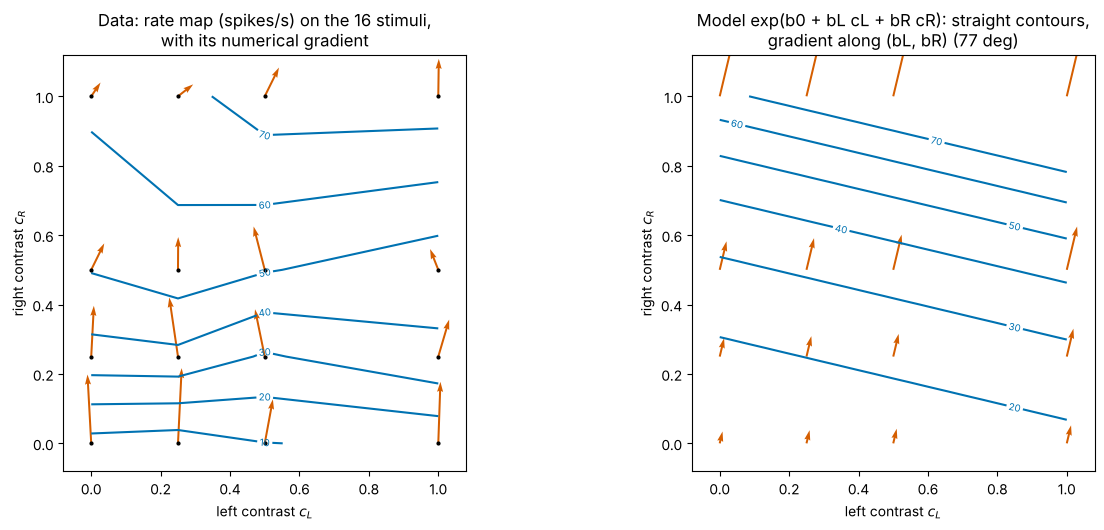

In [12]:
D_tr = np.column_stack([np.ones(len(y_tr)), cL_tr, cR_tr])             # (340, 3) design: intercept, c_L, c_R
def poisson_loss(b, D=D_tr, y=y_tr):
    z = D @ b
    return np.mean(np.exp(z) - y * z)
def poisson_grad(b, D=D_tr, y=y_tr):
    return D.T @ (np.exp(D @ b) - y) / len(y)                          # (3,) gradient of the mean loss
def poisson_hess(b, D=D_tr):
    lam = np.exp(D @ b)
    return (D * lam[:, None]).T @ D / len(lam)                         # (3, 3) Hessian: (1/n) sum lam_t d_t d_t^T

b = np.array([np.log(y_tr.mean()), 0.0, 0.0])
for it in range(25):
    b = b - np.linalg.solve(poisson_hess(b), poisson_grad(b))          # Newton step in 3 dimensions (Lesson 11, now with a Hessian)
print(f"fitted b = {np.round(b, 4)};  |gradient of the loss| at the fit = {np.linalg.norm(poisson_grad(b)):.1e}")
b_chk = b + np.array([0.1, -0.05, 0.05])                                # gradient check away from the minimum
print(f"gradient check at a nearby point: formula {np.round(poisson_grad(b_chk), 6)}, numerical {np.round(numerical_gradient(poisson_loss, b_chk, 1e-6), 6)}")
pd_deg = np.degrees(np.arctan2(b[2], b[1]))
print(f"gradient direction of the model {pd_deg:.1f} deg (0 = left only, 90 = right only);  "
      f"rate x e^b_R = x {np.exp(b[2]):.2f} from right contrast 0 to 1, x e^b_L = x {np.exp(b[1]):.2f} from left 0 to 1")

cc = np.linspace(0, 1, 41); CLg, CRg = np.meshgrid(cc, cc)
lam_map = np.exp(b[0] + b[1] * CLg + b[2] * CRg) / WIN                  # (41, 41) model rate, spikes/s
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
clev = [10, 20, 30, 40, 50, 60, 70]
cs0 = axes[0].contour(levels, levels, rate_map, levels=clev, colors=[PALETTE[0]])
axes[0].clabel(cs0, fontsize=7, fmt='%g')
GL, GR = np.meshgrid(levels, levels)
axes[0].quiver(GL, GR, dL_map, dR_map, color=PALETTE[1], angles='xy', scale_units='xy', scale=600, width=0.005)
axes[0].plot(GL, GR, 'k.', ms=4)
axes[0].set_title('Data: rate map (spikes/s) on the 16 stimuli,\nwith its numerical gradient')
cs1 = axes[1].contour(CLg, CRg, lam_map, levels=clev, colors=[PALETTE[0]])
axes[1].clabel(cs1, fontsize=7, fmt='%g')
qL, qR = np.meshgrid(levels, levels)
lam_q = np.exp(b[0] + b[1] * qL + b[2] * qR) / WIN
axes[1].quiver(qL, qR, lam_q * b[1], lam_q * b[2], color=PALETTE[1], angles='xy', scale_units='xy', scale=600, width=0.005)
axes[1].set_title(f'Model exp(b0 + bL cL + bR cR): straight contours,\ngradient along (bL, bR) ({pd_deg:.0f} deg)')
for ax in axes:
    ax.set_aspect('equal'); ax.set_xlabel('left contrast $c_L$'); ax.set_ylabel('right contrast $c_R$')
    ax.set_xlim(-0.08, 1.08); ax.set_ylim(-0.08, 1.12)
plt.tight_layout(); plt.show()

Both gradients point almost straight "up" the right-contrast axis: the neuron responds to the right (contralateral) grating and hardly to the left one. The numerical gradient of the data and the model's gradient agree in direction within about ten degrees.

They disagree about **how the slope changes**. In the data, the arrows are longest at the bottom (low right contrast) and shrink as the right contrast grows; in the model they grow. That is a statement about **second derivatives**.

### Curvature: the data bend one way, the model the other

The second partial derivative $\partial^2\lambda/\partial c_R^2$ is the $(R, R)$ entry of the Hessian of the rate surface. For the model, $\partial^2\lambda/\partial c_R^2 = \lambda\,b_R^2 > 0$ everywhere: an exponential always curves upwards. For the data we can estimate it by differentiating the numerical partial derivative again.

data, second partial d2/dc_R^2 (rows c_R, columns c_L):
 [[-125. -111.   23. -170.]
 [-147. -147.   -3. -141.]
 [-127. -146.  -35.  -55.]
 [ -44.  -72.  -50.   58.]]
mean over the grid: d2/dc_R^2 = -81,  mixed d2/dc_L dc_R = 3  (spikes/s per unit contrast^2)
model d2/dc_R^2 = lambda b_R^2: from 36 to 316, always positive


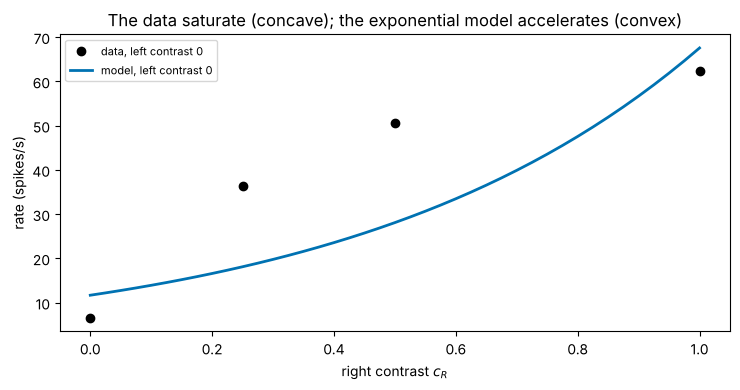

In [13]:
dRR_map = np.gradient(dR_map, levels, axis=0)                           # second partial in c_R, spikes/s per (unit contrast)^2
dLR_map = np.gradient(dR_map, levels, axis=1)                           # mixed partial d2/dc_L dc_R
print("data, second partial d2/dc_R^2 (rows c_R, columns c_L):\n", np.round(dRR_map, 0))
print(f"mean over the grid: d2/dc_R^2 = {dRR_map.mean():.0f},  mixed d2/dc_L dc_R = {dLR_map.mean():.0f}  (spikes/s per unit contrast^2)")
model_dRR = lam_q * b[2]**2
print(f"model d2/dc_R^2 = lambda b_R^2: from {model_dRR.min():.0f} to {model_dRR.max():.0f}, always positive")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(levels, rate_map[:, 0], 'o', color='black', label='data, left contrast 0')
ax.plot(cc, np.exp(b[0] + b[2] * cc) / WIN, color=PALETTE[0], lw=2, label='model, left contrast 0')
ax.set_xlabel('right contrast $c_R$'); ax.set_ylabel('rate (spikes/s)')
ax.set_title('The data saturate (concave); the exponential model accelerates (convex)')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The data's second partial in $c_R$ is negative over most of the grid: the response **saturates**, rising steeply from contrast 0 to 0.25 and then levelling off. The model's is positive everywhere. Both have the same gradient *direction*, but a model with the wrong curvature gets the rate badly wrong in places: at right contrast 0.5 it predicts about 28 spikes/s where the neuron fires about 50. The sign of a second derivative is not a detail; it decides the shape. (Capturing it needs a saturating input, such as the logarithm of contrast or a Naka–Rushton function, instead of contrast itself.)

### Directional derivatives: predicting the response to both screens

What happens when **both** contrasts rise together, along $\mathbf{u} = (1, 1)/\sqrt2$? The linear approximation says the change is the directional derivative, $D_{\mathbf{u}}\lambda = \nabla\lambda\cdot\mathbf{u} = \lVert\nabla\lambda\rVert\cos\phi$, where $\phi$ is the angle between $\mathbf{u}$ and the gradient. Using finite differences from the blank screen to full contrast, the left and right slopes estimate the two partial derivatives, and the slope along the diagonal should follow from them.

In [14]:
r00, r10, r01, r11 = rate_map[0, 0], rate_map[0, 3], rate_map[3, 0], rate_map[3, 3]     # blank, left 1, right 1, both 1
grad_fd = np.array([r10 - r00, r01 - r00])                              # finite-difference partials over one unit of contrast
u_both = np.array([1.0, 1.0]) / np.sqrt(2)
pred_slope = grad_fd @ u_both                                           # directional derivative from the gradient
meas_slope = (r11 - r00) / np.sqrt(2)                                   # measured slope along the diagonal (distance sqrt 2)
phi = np.degrees(np.arccos(pred_slope / np.linalg.norm(grad_fd)))
print(f"finite-difference gradient: ({grad_fd[0]:.1f}, {grad_fd[1]:.1f}) spikes/s per unit contrast")
print(f"slope along (1,1)/sqrt2: predicted {pred_slope:.1f} = |grad| cos({phi:.0f} deg), measured {meas_slope:.1f}")
print(f"linear prediction of the rate with both screens at full contrast: {r00 + grad_fd.sum():.1f} spikes/s;  measured {r11:.1f}")
print(f"the difference, r11 - r10 - r01 + r00 = {r11 - r10 - r01 + r00:.1f} spikes/s, is a finite-difference MIXED partial (trials: {n_map[3, 3]} with both)")

finite-difference gradient: (5.0, 55.8) spikes/s per unit contrast
slope along (1,1)/sqrt2: predicted 43.0 = |grad| cos(40 deg), measured 49.1
linear prediction of the rate with both screens at full contrast: 67.5 spikes/s;  measured 76.0
the difference, r11 - r10 - r01 + r00 = 8.5 spikes/s, is a finite-difference MIXED partial (trials: 5 with both)


The cosine rule predicts the diagonal slope to within about 15%. What it misses, $r_{11} - r_{10} - r_{01} + r_{00}$, is a finite-difference estimate of the **mixed** partial $\partial^2\lambda/\partial c_L\,\partial c_R$, the off-diagonal entry of the Hessian: how much the right contrast's effect changes when the left grating is also on. It rests on only 5 trials with both screens at full contrast, so it is a rough estimate.

### The Hessian of the loss, and units

At the fit, the Hessian of the **loss** is $\mathbf{H} = \frac1n\sum_t\lambda_t\,\mathbf{d}_t\mathbf{d}_t^{\mathsf T}$ with $\mathbf{d}_t = (1, c_{L,t}, c_{R,t})$. All its eigenvalues are positive (the loss is convex: a unique minimum). Its condition number depends on the **units** of the features. Contrast is often reported in percent; here we try that for the left contrast only.

In [15]:
def fit_poisson(D, y, iters=30):
    bb = np.zeros(D.shape[1]); bb[0] = np.log(y.mean())
    for _ in range(iters):
        bb -= np.linalg.solve(poisson_hess(bb, D), poisson_grad(bb, D, y))
    return bb
X_frac = np.column_stack([cL_tr, cR_tr])                               # (340, 2) fractions
X_mixed = X_frac * np.array([100.0, 1.0])                               # left in percent, right as a fraction
X_std = (X_frac - X_frac.mean(axis=0)) / X_frac.std(axis=0)             # standardised
print(f"{'features':<28}{'b (intercept, cL, cR)':>32}{'Hessian eigenvalues':>40}{'condition':>11}")
for lab, Xf, unit_back in [('fraction, fraction', X_frac, np.array([1.0, 1.0])),
                           ('percent (L), fraction (R)', X_mixed, np.array([100.0, 1.0])),
                           ('standardised', X_std, 1 / X_frac.std(axis=0))]:
    Df = np.column_stack([np.ones(len(y_tr)), Xf])
    bf = fit_poisson(Df, y_tr)
    ev = np.linalg.eigvalsh(poisson_hess(bf, Df))
    w_back = bf[1:] * unit_back                                         # weights converted back to "per unit contrast"
    print(f"{lab:<28}{str(np.round(bf, 4)):>32}{'  '.join(f'{e:.3g}' for e in ev):>40}{ev[-1] / ev[0]:>11,.0f}   (direction in fraction units: {np.degrees(np.arctan2(w_back[1], w_back[0])):.1f} deg)")

features                               b (intercept, cL, cR)                     Hessian eigenvalues  condition
fraction, fraction                    [0.8489 0.4182 1.7548]                         0.53  1.03  9.5         18   (direction in fraction units: 76.6 deg)
percent (L), fraction (R)             [0.8489 0.0042 1.7548]                   0.653  5.44  1.46e+04     22,288   (direction in fraction units: 76.6 deg)
standardised                          [1.54   0.1535 0.6909]                        2.91  6.32  13.5          5   (direction in fraction units: 76.6 deg)


**Interpretation.**
- **The neuron's response surface has a clear gradient**, pointing almost along the right-contrast axis: the same direction whether estimated from the 16 noisy averages or from the model. Lesson 2 found the same direction with a straight-line model; the direction of the gradient is robust to the choice of model.
- **The curvature is not.** The data saturate (negative second partial in $c_R$); the exponential model cannot, so it over-predicts at the blank screen and under-predicts at medium contrast. Gradient direction and curvature are different questions, answered by first and second derivatives.
- **Directional derivatives combine the partials** by the cosine rule, and predict the slope along the diagonal reasonably well; the remainder is a mixed second derivative.
- **The fitted model is identical in every set of units.** Its predictions and gradient direction (converted back) do not change. But measuring $c_L$ in percent divides its weight by 100 and multiplies the corresponding curvature of the loss by $10^4$: the condition number of the Hessian jumps from about 20 to over 20,000, and standardising brings it to about 5. Newton's method does not care (it is invariant to rescaling), but gradient descent does (Lesson 15).

**Limitations.** One neuron; some stimuli have only 5–7 trials, so second differences on this coarse, uneven grid are noisy; the counting window starts 50 ms after the stimulus and the response also reflects the mouse's movements; the log-linear model has the wrong curvature for a saturating response.

# **Part 6: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Functions of several variables | rate maps (place, grid and head-direction cells); receptive fields over visual space; tuning to several features | losses over many parameters; feature spaces |
| Partial derivatives | sensitivity of a response to one stimulus feature at a time | each component of a gradient (Lesson 10's backpropagation computes all of them) |
| Gradient and directional derivative | preferred direction as a gradient; cosine tuning; gradients of concentration followed by axon growth cones and chemotaxing cells | steepest-descent direction (Lesson 15); input-gradient saliency maps |
| Contour maps and level sets | iso-response contours in psychophysics; nullclines in phase planes (Lesson 23) | loss landscapes; decision boundaries of classifiers (a level set) |
| Hessian, saddles | maxima of rate maps (field centres); saddles between subfields; stability of fixed points (Jacobian, Lesson 23) | saddle points in high-dimensional losses; second-order optimisers; Fisher information = Hessian of the Poisson / logistic loss |
| Feature scaling and units | comparing sensitivities across stimulus features | standardisation, batch normalisation, preconditioning (Lesson 15) |

**Chemotaxis and growth cones.** A growing axon or a bacterium cannot see a chemical gradient: it samples concentrations and moves preferentially in the direction where they increase, estimating a directional derivative over its own length. Very shallow gradients (a 1–2% difference across a growth cone) are enough.

# **Part 7: Summary and Lesson 15 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Partial derivative | $\partial f/\partial x_i$: others held fixed | slope of a slice; units per unit of $x_i$ |
| Gradient | $\nabla f = (\partial f/\partial x_1, \dots)^{\mathsf T}$ | points uphill; length = steepest slope |
| Linear approximation | $f(\mathbf{x} + \mathbf{h}) \approx f + \nabla f\cdot\mathbf{h}$ | a tangent plane |
| Directional derivative | $D_{\mathbf{u}}f = \nabla f\cdot\mathbf{u} = \lVert\nabla f\rVert\cos\phi$ | cosine of the angle to the gradient: cosine tuning |
| Contours | level sets $f = c$ | perpendicular to the gradient; crowded = steep |
| Critical point | $\nabla f = \mathbf{0}$ | minimum, maximum or **saddle** |
| Hessian | $H_{ij} = \partial^2f/\partial x_i\partial x_j$ | eigenvalues = curvatures; signs classify the critical point |
| Units and scaling | rescaling $x_i$ by $c$ scales $\partial f/\partial x_i$ by $1/c$ and curvature by $1/c^2$ | standardise before comparing; condition number |
| Numerics | `np.gradient` on grids; central differences per input | rows/columns order: `np.gradient(Z, y, x)` returns ($\partial_y$, $\partial_x$) |

**Lesson 15 — Multidimensional optimisation.** Gradient descent in many dimensions, $\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\nabla L$, walks perpendicular to the contours. In the elongated valleys created by badly scaled or correlated features it zig-zags; Lesson 15 studies this with the condition number, and the remedies: feature scaling, preconditioning, momentum, and regularisation.